# Experiment 7 · Reaction time and lookahead against the planning horizon

**Date:** 2026-11-08 · **Agents:** `v2_catch_s1`–`s20` minus `s7` (19 competent seeds, see Experiment 6) · **Status:** group level, 19 seeds

## Question
Does the agent take longer to start moving when there are more targets to plan for, and how
much lookahead (co-articulation) does it show for each sequence length? In people, RT grows
with the number of elements in a prepared sequence (the sequence-length effect), which is read
as evidence that the whole sequence is planned before movement starts.

## Design
**Geometry-matched sequences.** For each seed, 1000 random geometries are drawn once:
start x₀ ~ U[−0.5, 0.5] (the v2 training range), targets T1, T2, T3 uniform in ±0.9 with the
training minimum separation, and a hold time from the training distribution (0.25–1.0 s).
Every geometry is replayed in five conditions:

| condition | targets | visible at trial onset | what the agent knows before go |
| --- | --- | --- | --- |
| `1 tgt` | T1 | T1 | one reach |
| `2 tgt` | T1 T2 | T1 T2 | both locations |
| `3 tgt` | T1 T2 T3 | T1 T2 T3 | all three locations |
| `2 tgt, H1` | T1 T2 | T1 only | *that* one more target follows, not where |
| `3 tgt, H1` | T1 T2 T3 | T1 only | *that* two more follow, not where |

So a 2-target trial is exactly the 1-target trial plus T2. Any difference in RT or in the
first reach comes from the extra targets, not from a different first reach. The horizon
(number of visible targets) is 1, 2, 3 in the full-preview conditions. The two H1 conditions
separate *how many targets follow* (the pending flags are still visible) from *where they are*.

Noiseless plant, mean action, no catch trials. 5000 trials per seed.

## Measures
- **RT (force onset).** The time from the true go step until the force on the mass, pushing
  toward T1, first reaches 2 (25% of u_max). The force is the command through the 50 ms
  actuator lag, so it is continuous and its threshold crossing can be interpolated. RT
  includes the 80 ms cue delay, so the floor is 80 ms. The policy's command itself is held
  for a whole 20 ms step, so a command-based RT would be quantised to 80/100/120 ms; it is
  reported as `rt_u_ms` for reference. **Per seed, the median over trials** is used, because a
  few trials respond very late and drag the mean.
- **CI (co-articulation index).** The velocity on first entering T1, signed in the direction
  of the first reach (v_out), regressed on d_next = (T2 − T1) in the same frame (+ = T2
  continues onward). With T1 and the start random, v_out depends strongly on the first reach
  itself, so the CI is the *partial* slope of v_out on d_next, controlling for a cubic
  polynomial in (x₀, T1). The H1 conditions are the **empirical null**: there T2 is
  invisible until T1 is entered, so the true slope is exactly 0.
- **3-target extras.** `ci_T3` asks whether T3 changes the exit speed at T1 beyond T2.
  `ci_2` is lookahead at T2 toward T3.
- First-reach peak speed and movement time to T1.

Group statistics are across seeds. Each seed contributes one number per condition, with
Wilcoxon signed-rank tests for the paired comparisons and a Friedman test over the 1/2/3
horizon.

In [1]:
from exp_tools import *
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import display

use_style()
pd.set_option("display.precision", 3)
comp = pd.read_csv("exp06_task_drift.csv")
comp = comp[comp.group == "v2_catch"]
RUNS_V2 = comp[comp.competent].run.tolist()
print(len(RUNS_V2), "competent seeds; excluded:", comp[~comp.competent].run.tolist())
FULL = ["1 tgt", "2 tgt", "3 tgt"]
H1 = ["2 tgt, H1", "3 tgt, H1"]
ORDER = FULL + H1
CCOL = {"1 tgt": INK_SOFT, "2 tgt": BLUE, "3 tgt": AQUA, "2 tgt, H1": ORANGE, "3 tgt, H1": "#c0392b"}

19 competent seeds; excluded: ['v2_catch_s7']


## Example: one geometry, three sequence lengths (seed 1)

The same start, the same T1 and the same go time. Only the number of targets after T1 changes.

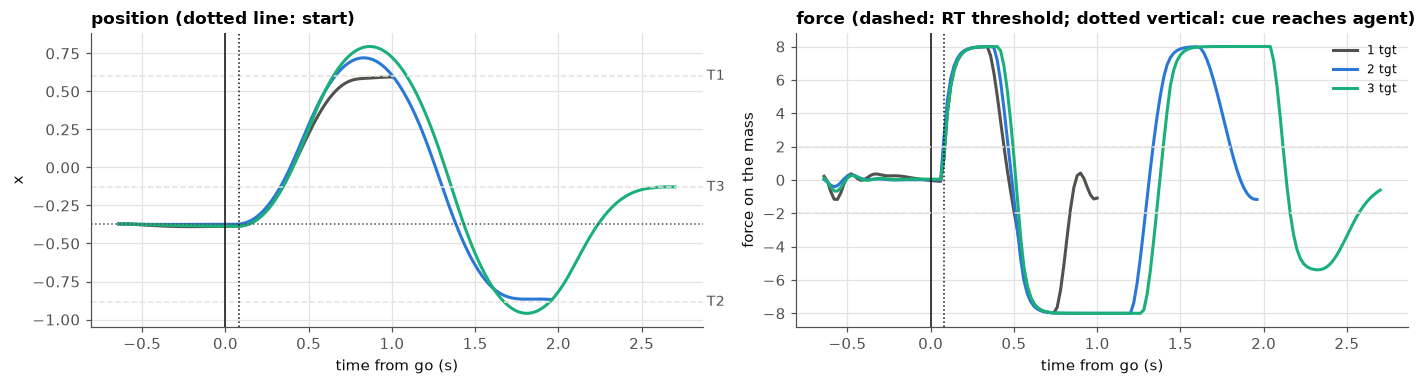

     cond   rt_ms  rt_u_ms  peak_v1  mt1_ms  v_out  d_next
    1 tgt 105.164     80.0    2.321 634.836  0.728  -1.486
    2 tgt  95.520     80.0    2.591 564.480  1.635  -1.486
    3 tgt 104.731     80.0    2.762 555.269  1.932  -1.486
2 tgt, H1 100.841     80.0    2.556 579.159  1.482  -1.486
3 tgt, H1  92.748     80.0    2.579 567.252  1.478  -1.486


In [2]:
df1, geo1, tr1 = horizon_probe(RUNS / "v2_catch_s1", n_geom=1000, return_traj=True)
# a geometry where the sequence zig-zags, so lookahead is visible
g = geo1
zig = np.flatnonzero((np.sign(g["targets"][:, 0] - g["x0"]) != np.sign(g["targets"][:, 1] - g["targets"][:, 0]))
                     & (np.abs(g["targets"][:, 0] - g["x0"]) > 0.5)
                     & (np.sign(g["targets"][:, 2] - g["targets"][:, 1]) != np.sign(g["targets"][:, 1] - g["targets"][:, 0])))[0]
n_geom, dt = len(g["x0"]), g["dt"]
fig, axs = plt.subplots(1, 2, figsize=(13, 3.6))
for c, cond in enumerate(ORDER[:3]):
    i = c * n_geom + zig
    go, end = int(tr1["go_step"][i]), int(tr1["end_step"][i])
    tt = (np.arange(end + 1) - go) * dt
    axs[0].plot(tt, tr1["x"][:end + 1, i], color=CCOL[cond], lw=2, label=cond)
    axs[1].plot(tt, tr1["a"][:end + 1, i], color=CCOL[cond], lw=2, label=cond)
for k, T in enumerate(g["targets"][zig]):
    axs[0].axhline(T, color=GRID, ls="--", lw=1)
    axs[0].text(axs[0].get_xlim()[1], T, f" T{k+1}", va="center", fontsize=9, color=INK_SOFT)
axs[0].axhline(g["x0"][zig], color=INK_SOFT, ls=":", lw=1)
for ax in axs:
    ax.axvline(0, color=INK, lw=1); ax.axvline(0.08, color=INK, lw=1, ls=":")
    ax.set_xlabel("time from go (s)")
axs[1].axhline(2, color=GRID, ls="--", lw=1); axs[1].axhline(-2, color=GRID, ls="--", lw=1)
axs[0].set_ylabel("x"); axs[1].set_ylabel("force on the mass")
axs[0].set_title("position (dotted line: start)"); axs[1].set_title("force (dashed: RT threshold; dotted vertical: cue reaches agent)")
axs[1].legend(fontsize=8)
plt.tight_layout(); plt.show()
print(df1[df1.geom == zig][["cond", "rt_ms", "rt_u_ms", "peak_v1", "mt1_ms", "v_out", "d_next"]].to_string(index=False))

## Run the probe on all 19 seeds

In [3]:
all_trials, ci_rows = [], []
for r in RUNS_V2:
    df, _ = horizon_probe(RUNS / r, n_geom=1000)
    df["run"] = r
    all_trials.append(df)
    for cond, res in horizon_ci(df).items():
        ci_rows.append({"run": r, "cond": cond, **res})
trials = pd.concat(all_trials, ignore_index=True)
ci = pd.DataFrame(ci_rows)
print(len(trials), "trials")

95000 trials


### Competence per condition

RT and CI are read off successful trials only. Check first that every condition is performed.

In [4]:
succ = trials.pivot_table(index="run", columns="cond", values="success", aggfunc="mean")[ORDER]
print("success rate per condition, across seeds:")
display(succ.agg(["mean", "min"]))
fs = trials.pivot_table(index="run", columns="cond", values="false_start", aggfunc="mean")[ORDER]
print("false starts (mean across seeds):", fs.mean().round(4).to_dict())

success rate per condition, across seeds:


cond,1 tgt,2 tgt,3 tgt,"2 tgt, H1","3 tgt, H1"
mean,1.0,0.998,0.996,1.0,0.996
min,1.0,0.987,0.961,1.0,0.946


false starts (mean across seeds): {'1 tgt': 0.0, '2 tgt': 0.0, '3 tgt': 0.0001, '2 tgt, H1': 0.0, '3 tgt, H1': 0.0}


### Per-seed summaries

In [5]:
ok = trials[trials.success]
per = ok.groupby(["run", "cond"]).agg(
    rt_med=("rt_ms", "median"), rt_mean=("rt_ms", "mean"), rt_u_mean=("rt_u_ms", "mean"),
    late=("rt_ms", lambda x: (x > 150).mean()), wrong_way=("wrong_way", "mean"),
    peak_v1=("peak_v1", "median"), mt1=("mt1_ms", "median"), v_out=("v_out", "median")).reset_index()
rt = per.pivot(index="run", columns="cond", values="rt_med")[ORDER]
print("median RT (ms) per seed")
display(rt.round(1))
print("group: mean ± sd across seeds of the per-seed medians")
display(pd.DataFrame({"mean": rt.mean(), "sd": rt.std(), "min": rt.min(), "max": rt.max()}).T.round(1))

median RT (ms) per seed


cond,1 tgt,2 tgt,3 tgt,"2 tgt, H1","3 tgt, H1"
run,,,,,
v2_catch_s1,96.3,97.9,105.2,96.6,95.7
v2_catch_s10,104.1,105.9,106.2,106.7,107.5
v2_catch_s11,103.6,101.0,99.0,104.8,106.9
v2_catch_s12,103.6,103.2,102.7,105.1,103.3
v2_catch_s13,106.9,106.0,103.1,105.1,93.0
v2_catch_s14,104.3,100.4,107.4,98.6,100.6
v2_catch_s15,102.9,104.7,100.1,103.9,106.8
v2_catch_s16,102.8,100.9,102.7,98.6,95.6
v2_catch_s17,101.7,103.8,105.2,102.0,101.9


group: mean ± sd across seeds of the per-seed medians


cond,1 tgt,2 tgt,3 tgt,"2 tgt, H1","3 tgt, H1"
mean,103.1,102.6,103.3,102.5,101.4
sd,2.6,3.2,3.8,3.2,4.4
min,96.3,94.2,93.0,95.4,93.0
max,106.9,107.0,110.2,106.7,108.4


## RT against the horizon

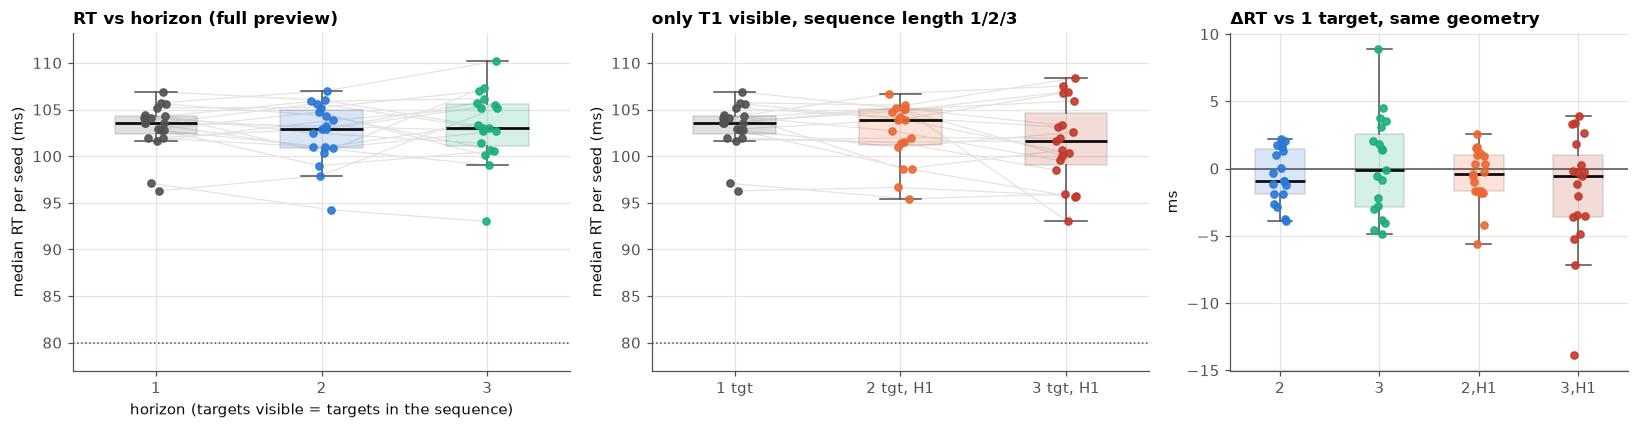

In [6]:
def boxdots(ax, table, conds, paired=True, jitter=0.07):
    rng = np.random.default_rng(0)
    data = [table[c].dropna().to_numpy() for c in conds]
    pos = np.arange(len(conds))
    bp = ax.boxplot(data, positions=pos, widths=0.5, showfliers=False, patch_artist=True,
                    medianprops=dict(color=INK, lw=1.8), whiskerprops=dict(color=INK_SOFT),
                    capprops=dict(color=INK_SOFT), boxprops=dict(edgecolor=INK_SOFT))
    for patch, c in zip(bp["boxes"], conds):
        patch.set_facecolor(CCOL[c]); patch.set_alpha(0.18)
    xs = {c: p + rng.uniform(-jitter, jitter, len(table)) for c, p in zip(conds, pos)}
    if paired:
        for j in range(len(table)):
            ax.plot([xs[c][j] for c in conds], [table[c].iloc[j] for c in conds],
                    color=GRID, lw=0.8, zorder=1)
    for c in conds:
        ax.scatter(xs[c], table[c], color=CCOL[c], s=22, zorder=3, alpha=0.9)
    ax.set_xticks(pos, conds)

fig, axs = plt.subplots(1, 3, figsize=(15, 4), gridspec_kw={"width_ratios": [3, 3, 2.4]})
boxdots(axs[0], rt, FULL)
axs[0].set_xticks(range(3), ["1", "2", "3"]); axs[0].set_xlabel("horizon (targets visible = targets in the sequence)")
axs[0].set_ylabel("median RT per seed (ms)"); axs[0].set_title("RT vs horizon (full preview)")
boxdots(axs[1], rt, ["1 tgt", "2 tgt, H1", "3 tgt, H1"])
axs[1].set_title("only T1 visible, sequence length 1/2/3")
axs[1].set_ylabel("median RT per seed (ms)")
for ax in axs[:2]:
    ax.axhline(80, color=INK_SOFT, ls=":", lw=1)
lo = min(rt.min().min(), 80) - 3; hi = rt.max().max() + 3
axs[0].set_ylim(lo, hi); axs[1].set_ylim(lo, hi)
d = rt[["2 tgt", "3 tgt", "2 tgt, H1", "3 tgt, H1"]].sub(rt["1 tgt"], axis=0)
boxdots(axs[2], d, list(d.columns), paired=False)
axs[2].axhline(0, color=INK_SOFT, lw=1)
axs[2].set_xticks(range(4), ["2", "3", "2,H1", "3,H1"])
axs[2].set_title("ΔRT vs 1 target, same geometry"); axs[2].set_ylabel("ms")
plt.tight_layout(); plt.show()

In [7]:
def wil(a, b=None):
    x = a if b is None else a - b
    x = x.dropna()
    p = stats.wilcoxon(x).pvalue if (x != 0).any() else 1.0
    return {"mean diff": x.mean(), "median diff": x.median(), "seeds >0": int((x > 0).sum()),
            "seeds <0": int((x < 0).sum()), "p (Wilcoxon)": p}

fr = stats.friedmanchisquare(rt["1 tgt"], rt["2 tgt"], rt["3 tgt"])
print(f"Friedman over horizon 1/2/3: chi2 = {fr.statistic:.2f}, p = {fr.pvalue:.3g}")
pairs = [("2 tgt", "1 tgt"), ("3 tgt", "1 tgt"), ("3 tgt", "2 tgt"),
         ("2 tgt, H1", "1 tgt"), ("3 tgt, H1", "1 tgt"), ("2 tgt", "2 tgt, H1"), ("3 tgt", "3 tgt, H1")]
rt_stats = pd.DataFrame({f"{a} − {b}": wil(rt[a], rt[b]) for a, b in pairs}).T
rt_stats

Friedman over horizon 1/2/3: chi2 = 0.74, p = 0.692


,mean diff,median diff,seeds >0,seeds <0,p (Wilcoxon)
2 tgt − 1 tgt,-0.510,-0.913,8.0,11.0,0.395
3 tgt − 1 tgt,0.192,-0.094,9.0,10.0,0.953
3 tgt − 2 tgt,0.702,1.355,11.0,8.0,0.490
"2 tgt, H1 − 1 tgt",-0.588,-0.403,8.0,11.0,0.241
"3 tgt, H1 − 1 tgt",-1.623,-0.550,6.0,13.0,0.104
"2 tgt − 2 tgt, H1",0.078,0.454,11.0,8.0,0.709
"3 tgt − 3 tgt, H1",1.815,1.803,12.0,7.0,0.123


### Is the RT effect in every trial, or in a tail of late responses?

Per seed: the fraction of trials with RT > 150 ms, the fraction with a brief push the wrong way before the response, and the mean RT. A shift of the whole distribution and a tail of hesitant trials mean different things.

cond,1 tgt,2 tgt,3 tgt,"2 tgt, H1","3 tgt, H1"
late (>150 ms),0.012,0.029,0.043,0.004,0.014
wrong-way first,0.017,0.034,0.059,0.004,0.027
mean RT,105.784,107.349,109.215,103.942,104.331
median RT,103.066,102.556,103.258,102.478,101.443


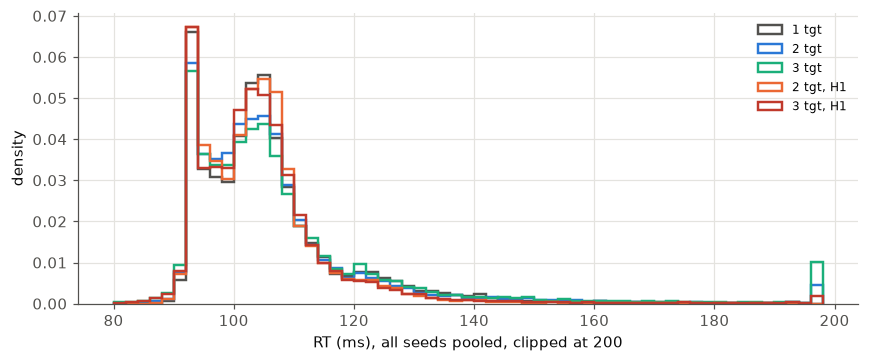

Friedman on mean RT over horizon 1/2/3: p = 0.00749


,mean diff,median diff,seeds >0,seeds <0,p (Wilcoxon)
mean RT: 2 tgt − 1 tgt,1.565,1.564,11.0,8.0,0.145
mean RT: 3 tgt − 1 tgt,3.431,2.250,15.0,4.0,0.040
late frac: 2 tgt − 1 tgt,0.017,0.014,15.0,3.0,0.014
late frac: 3 tgt − 1 tgt,0.031,0.022,15.0,4.0,0.005


In [8]:
tail = per.pivot(index="run", columns="cond", values="late")[ORDER]
ww = per.pivot(index="run", columns="cond", values="wrong_way")[ORDER]
rtm = per.pivot(index="run", columns="cond", values="rt_mean")[ORDER]
display(pd.DataFrame({"late (>150 ms)": tail.mean(), "wrong-way first": ww.mean(),
                      "mean RT": rtm.mean(), "median RT": rt.mean()}).T.round(3))
fig, ax = plt.subplots(figsize=(8, 3.4))
bins = np.arange(80, 200, 2)
for c in ORDER:
    ax.hist(ok[ok.cond == c].rt_ms.clip(upper=198), bins=bins, histtype="step", lw=1.6,
            color=CCOL[c], density=True, label=c)
ax.set_xlabel("RT (ms), all seeds pooled, clipped at 200"); ax.set_ylabel("density"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()
print("Friedman on mean RT over horizon 1/2/3: p =", f"{stats.friedmanchisquare(rtm['1 tgt'], rtm['2 tgt'], rtm['3 tgt']).pvalue:.3g}")
display(pd.DataFrame({**{f"mean RT: {a} − 1 tgt": wil(rtm[a], rtm["1 tgt"]) for a in ["2 tgt", "3 tgt"]},
                      **{f"late frac: {a} − 1 tgt": wil(tail[a], tail["1 tgt"]) for a in ["2 tgt", "3 tgt"]}}).T)

## RT depends on *where* the next target is

Same geometries, so each full-preview trial has an **H1 twin**: the same start, targets and
go time, and the same known number of targets, but with T2's location hidden. So
ΔRT = RT(full preview) − RT(H1 twin) isolates the effect of *seeing where T2 is*. It is split by
whether T2 **continues** in the direction of the first reach or **reverses**, and by the length
of the first reach (short < 0.4, long ≥ 0.4). Median per seed.

(Comparing with the 1-target twin instead is confounded: T2's direction is correlated with
where T1 sits, and the H1 trials already differ from the 1-target trials by a few ms
depending on the geometry.)

share of trials: short reach 0.35 | T2 reverses 0.80


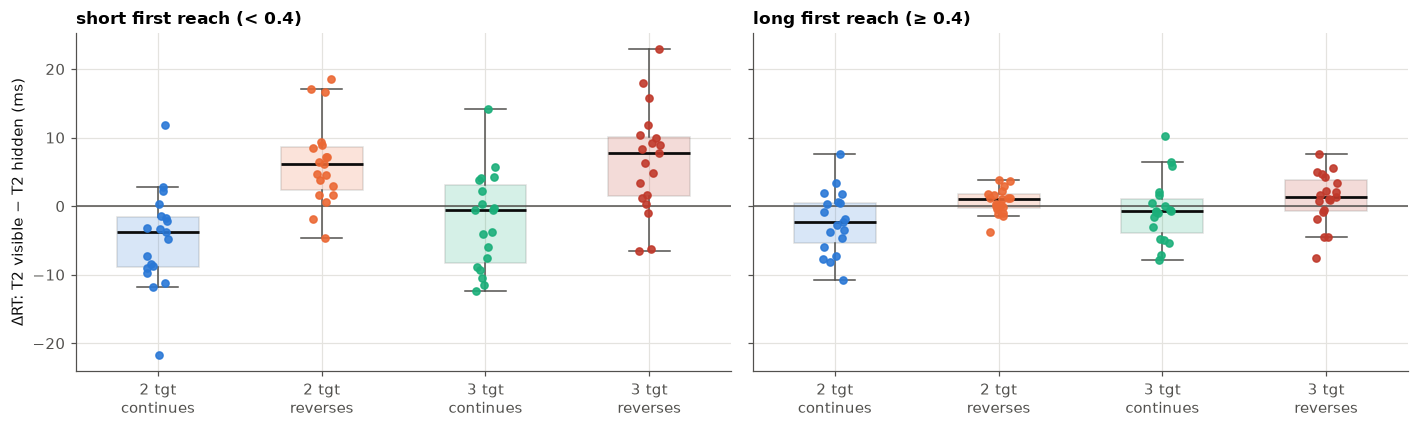

,mean diff,median diff,seeds >0,seeds <0,p (Wilcoxon)
short reach · 2 tgt · T2 continues,-4.806,-3.826,4.0,15.0,7.145e-03
short reach · 2 tgt · T2 reverses,6.268,6.121,17.0,2.0,3.357e-04
short reach · 3 tgt · T2 continues,-2.143,-0.544,7.0,12.0,1.956e-01
short reach · 3 tgt · T2 reverses,6.693,7.693,16.0,3.0,9.651e-04
long reach · 2 tgt · T2 continues,-2.299,-2.365,7.0,12.0,4.013e-02
long reach · 2 tgt · T2 reverses,0.707,1.091,13.0,6.0,1.042e-01
long reach · 3 tgt · T2 continues,-0.623,-0.740,7.0,12.0,3.736e-01
long reach · 3 tgt · T2 reverses,1.071,1.314,13.0,6.0,1.336e-01


In [9]:
wide = ok.pivot_table(index=["run", "geom"], columns="cond", values="rt_ms")
geo_cols = trials[trials.cond == "1 tgt"].set_index(["run", "geom"])[["dist1", "d_next"]]
dd = pd.DataFrame({"2 tgt": wide["2 tgt"] - wide["2 tgt, H1"],
                   "3 tgt": wide["3 tgt"] - wide["3 tgt, H1"]}).join(geo_cols)
dd["T2"] = np.where(dd.d_next > 0, "continues", "reverses")
dd["reach"] = np.where(dd.dist1 < 0.4, "short", "long")
split = dd.groupby(["run", "reach", "T2"])[["2 tgt", "3 tgt"]].median()
print("share of trials: short reach", f"{(dd.reach == 'short').mean():.2f}",
      "| T2 reverses", f"{(dd.T2 == 'reverses').mean():.2f}")
fig, axs = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
rows = {}
for ax, reach in zip(axs, ["short", "long"]):
    tab = {}
    for c in ["2 tgt", "3 tgt"]:
        for t2 in ["continues", "reverses"]:
            key = f"{c}\n{t2}"
            tab[key] = split.xs((reach, t2), level=("reach", "T2"))[c]
            CCOL[key] = CCOL[c] if t2 == "continues" else CCOL[c + ", H1"]
            rows[f"{reach} reach · {c} · T2 {t2}"] = wil(tab[key])
    tab = pd.DataFrame(tab)
    boxdots(ax, tab, list(tab.columns), paired=False)
    ax.axhline(0, color=INK_SOFT, lw=1)
    ax.set_title(f"{reach} first reach ({'< 0.4' if reach == 'short' else '≥ 0.4'})")
axs[0].set_ylabel("ΔRT: T2 visible − T2 hidden (ms)")
plt.tight_layout(); plt.show()
rt_dir_stats = pd.DataFrame(rows).T
rt_dir_stats

## Lookahead (CI) by condition

The H1 conditions are the null (true slope 0). `ci_T3`: effect of T3 on the exit speed at T1 beyond T2. `ci_2`: lookahead at T2 toward T3.

In [10]:
ci_tab = ci.pivot(index="run", columns="cond", values="ci")[["2 tgt", "3 tgt"] + H1]
ex = ci[ci.cond.isin(["3 tgt", "3 tgt, H1"])].pivot(index="run", columns="cond", values=["ci_T3", "ci_2"])
ex.columns = [f"{m} ({c})" for m, c in ex.columns]
ci_all = ci_tab.join(ex)
display(ci_all.agg(["mean", "std", "min", "max"]).T.round(3))
ci_stats = pd.DataFrame({c: wil(ci_all[c]) for c in ci_all.columns}).T
ci_stats["vs 0"] = "p (Wilcoxon) tests median ≠ 0"
display(ci_stats.drop(columns="vs 0"))
print("3 tgt vs 2 tgt CI:", wil(ci_all["3 tgt"], ci_all["2 tgt"]))

,mean,std,min,max
2 tgt,0.527,0.141,0.299,0.785
3 tgt,0.406,0.152,0.173,0.724
"2 tgt, H1",-0.003,0.011,-0.022,0.023
"3 tgt, H1",-0.000,0.014,-0.026,0.026
ci_T3 (3 tgt),0.127,0.151,-0.222,0.453
"ci_T3 (3 tgt, H1)",-0.002,0.005,-0.012,0.007
ci_2 (3 tgt),0.408,0.197,-0.001,0.661
"ci_2 (3 tgt, H1)",0.023,0.024,-0.021,0.063


,mean diff,median diff,seeds >0,seeds <0,p (Wilcoxon)
2 tgt,5.274e-01,0.535,19.0,0.0,3.815e-06
3 tgt,4.064e-01,0.352,19.0,0.0,3.815e-06
"2 tgt, H1",-3.355e-03,-0.002,6.0,13.0,2.101e-01
"3 tgt, H1",-8.862e-05,-0.002,8.0,11.0,7.983e-01
ci_T3 (3 tgt),1.275e-01,0.164,16.0,3.0,5.329e-03
"ci_T3 (3 tgt, H1)",-2.483e-03,-0.001,9.0,10.0,1.564e-01
ci_2 (3 tgt),4.075e-01,0.466,18.0,1.0,7.629e-06
"ci_2 (3 tgt, H1)",2.311e-02,0.024,16.0,3.0,7.896e-04


3 tgt vs 2 tgt CI: {'mean diff': -0.12103274621055941, 'median diff': -0.1232663647536163, 'seeds >0': 4, 'seeds <0': 15, 'p (Wilcoxon)': 0.002838134765625}


### Null-corrected CI (ΔCI)

The H1 null is not exactly 0: a cubic control leaves a little non-linear geometry in the
regression (largest for `ci_2`, about +0.02). Because the geometries are matched, subtracting
the H1 estimate from the full-preview estimate removes that bias. This is ΔCI =
CI(visible) − CI(hidden), the project's usual convention (`delta_ci` in `metrics.py`).

In [11]:
dci = pd.DataFrame({
    "ΔCI at T1, 2 tgt": ci_all["2 tgt"] - ci_all["2 tgt, H1"],
    "ΔCI at T1, 3 tgt": ci_all["3 tgt"] - ci_all["3 tgt, H1"],
    "Δ T3→exit T1": ci_all["ci_T3 (3 tgt)"] - ci_all["ci_T3 (3 tgt, H1)"],
    "ΔCI at T2 (→T3)": ci_all["ci_2 (3 tgt)"] - ci_all["ci_2 (3 tgt, H1)"]})
pd.DataFrame({c: wil(dci[c]) for c in dci}).T

,mean diff,median diff,seeds >0,seeds <0,p (Wilcoxon)
"ΔCI at T1, 2 tgt",0.531,0.535,19.0,0.0,3.815e-06
"ΔCI at T1, 3 tgt",0.406,0.358,19.0,0.0,3.815e-06
Δ T3→exit T1,0.130,0.170,16.0,3.0,3.918e-03
ΔCI at T2 (→T3),0.384,0.434,18.0,1.0,1.144e-05


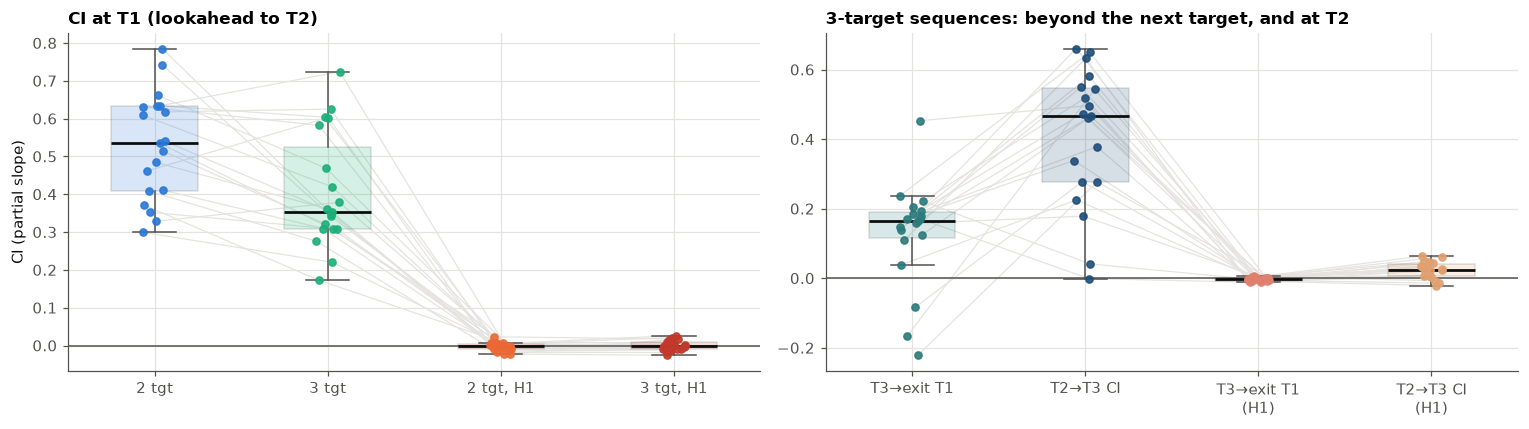

In [12]:
CCOL.update({"ci_T3 (3 tgt)": "#2c7a7b", "ci_2 (3 tgt)": "#1f4e79",
             "ci_T3 (3 tgt, H1)": "#e08070", "ci_2 (3 tgt, H1)": "#e0a070"})
fig, axs = plt.subplots(1, 2, figsize=(14, 4), gridspec_kw={"width_ratios": [4, 4]})
boxdots(axs[0], ci_all, ["2 tgt", "3 tgt", "2 tgt, H1", "3 tgt, H1"])
axs[0].set_title("CI at T1 (lookahead to T2)"); axs[0].set_ylabel("CI (partial slope)")
cols = ["ci_T3 (3 tgt)", "ci_2 (3 tgt)", "ci_T3 (3 tgt, H1)", "ci_2 (3 tgt, H1)"]
boxdots(axs[1], ci_all, cols)
axs[1].set_xticks(range(4), ["T3→exit T1", "T2→T3 CI", "T3→exit T1\n(H1)", "T2→T3 CI\n(H1)"])
axs[1].set_title("3-target sequences: beyond the next target, and at T2")
for ax in axs:
    ax.axhline(0, color=INK_SOFT, lw=1)
plt.tight_layout(); plt.show()

## The first reach itself

If the agent plans through T1 when it can see more targets, the first reach should be faster and shorter in time and should leave T1 still moving. Median per seed.

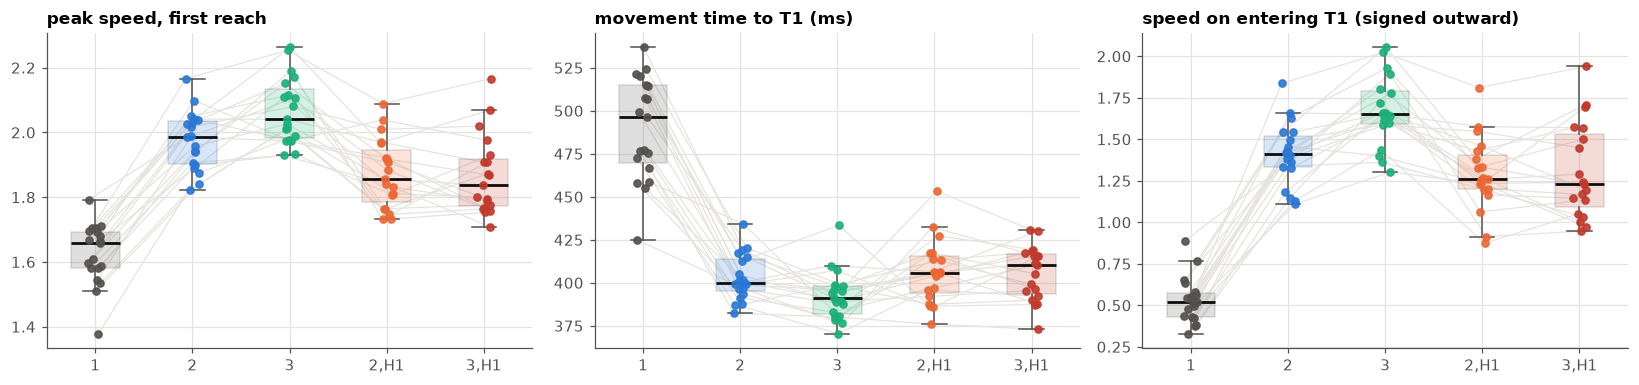

,peak_v1,mt1,v_out
cond,,,
1 tgt,1.626,489.849,0.531
2 tgt,1.974,403.203,1.410
3 tgt,2.069,392.502,1.672
"2 tgt, H1",1.873,406.510,1.292
"3 tgt, H1",1.867,405.881,1.308


In [13]:
fig, axs = plt.subplots(1, 3, figsize=(15, 3.6))
for ax, (col, title) in zip(axs, [("peak_v1", "peak speed, first reach"), ("mt1", "movement time to T1 (ms)"),
                                  ("v_out", "speed on entering T1 (signed outward)")]):
    tab = per.pivot(index="run", columns="cond", values=col)[ORDER]
    boxdots(ax, tab, ORDER)
    ax.set_xticks(range(5), ["1", "2", "3", "2,H1", "3,H1"]); ax.set_title(title)
plt.tight_layout(); plt.show()
first = per.groupby("cond")[["peak_v1", "mt1", "v_out"]].mean().loc[ORDER]
first

## Do seeds with more lookahead slow down more?

Across seeds: the RT cost of the full 3-target horizon against the CI with 2 targets.

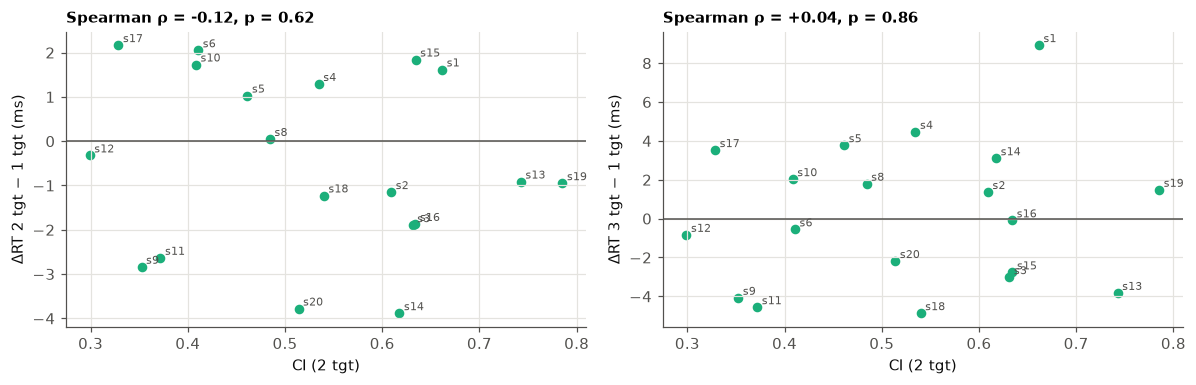

In [14]:
x = ci_all["2 tgt"]; y = (rt["3 tgt"] - rt["1 tgt"]).loc[x.index]
y2 = (rt["2 tgt"] - rt["1 tgt"]).loc[x.index]
fig, axs = plt.subplots(1, 2, figsize=(11, 3.6))
for ax, yy, lab in zip(axs, [y2, y], ["ΔRT 2 tgt − 1 tgt (ms)", "ΔRT 3 tgt − 1 tgt (ms)"]):
    ax.scatter(x, yy, color=AQUA, s=28)
    for r_ in x.index:
        ax.annotate(r_.replace("v2_catch_", ""), (x[r_], yy[r_]), fontsize=7, color=INK_SOFT,
                    xytext=(3, 2), textcoords="offset points")
    rho = stats.spearmanr(x, yy)
    ax.set_title(f"Spearman ρ = {rho.statistic:+.2f}, p = {rho.pvalue:.2g}", fontsize=10)
    ax.axhline(0, color=INK_SOFT, lw=1); ax.set_xlabel("CI (2 tgt)"); ax.set_ylabel(lab)
plt.tight_layout(); plt.show()

In [15]:
per.to_csv("exp07_per_seed_by_condition.csv", index=False)
split.reset_index().to_csv("exp07_rt_by_next_target.csv", index=False)
dci.to_csv("exp07_delta_ci.csv")
ci.to_csv("exp07_ci_per_seed.csv", index=False)
rt_stats.to_csv("exp07_rt_stats.csv")
print("saved")

saved


## Conclusion

**All five conditions are performed.** Mean success ≥ 0.996 in every condition (worst seed:
0.946 on `3 tgt, H1`), and there are no false starts. So RT and CI are read off a competent agent in
every cell.

### 1. RT does not grow with the horizon
- The typical RT is the same for 1, 2 and 3 targets. The median per seed is about 103 ms in every
  condition, and the 1→2→3 trend is flat (Friedman p = 0.69). The 3 − 1 target difference is
  +0.2 ms (9 seeds up, 10 down, p = 0.95). Hiding the later targets (H1) changes nothing either.
- That 103 ms is the 80 ms cue delay plus about 23 ms for the force to build to 25% of
  u_max through the actuator lag. In most trials the agent commands the reach **on the first
  step it can see the cue**. RT varies only through how hard that first command pushes.
- **There is no sequence-length effect** of the kind seen in people. That fits a network that
  updates all visible targets in parallel on every step. It also has at least 250 ms of hold
  to prepare, so these are prepared responses. A planning cost, if there is one, would
  have to show on unprepared trials (go at or near the start of the hold), which this probe
  does not test.

### 2. A small tail of slow or hesitant responses does grow with the horizon
- The fraction of trials with RT > 150 ms grows with the horizon: 1.2% → 2.9% → 4.3% for 1/2/3 targets (3 vs 1:
  15/19 seeds, p = 0.005).
- So does the fraction with a brief push *the wrong way* before the response: 1.7% → 3.4% → 5.9%.
- This tail lifts the **mean** RT slightly: 105.8 → 107.3 → 109.2 ms (Friedman p = 0.007; 3 vs 1
  p = 0.04). The effect is real but small, and it lives in a minority of trials.

### 3. What changes RT is *where* the next target is, not how many there are
Each trial is compared with its own H1 twin, which has the same geometry and the same known
number of targets but a hidden T2. Seeing T2:
- **slows** the response when T2 lies back the way the agent came and the first reach is
  short: +6 ms with 2 targets (17/19 seeds, p = 3 × 10⁻⁴) and +7 ms with 3 (16/19, p = 0.001);
- **speeds** it when T2 continues onward: −4 ms with 2 targets (15/19, p = 0.007);
- matters much less when the first reach is long (≥ 0.4).

The slow and wrong-way trials are mostly short first reaches with T2 behind the start.
**The T2 plan leaks into the T1 command:** the first push is weaker, or briefly toward T2,
when the two reaches pull in opposite directions. That is the signature of the two reaches
being prepared together and competing, not of extra planning time per target. The same
mechanism helps when T2 is in the same direction. It averages out over random geometries,
which is why the median RT is flat.

### 4. Lookahead is strong, reaches two targets ahead, and is measured cleanly
| measure | mean across seeds | seeds > 0 | p |
| --- | --- | --- | --- |
| CI at T1, 2 targets | **0.53** (0.30–0.79) | 19/19 | 4 × 10⁻⁶ |
| CI at T1, 3 targets | **0.41** (0.17–0.72) | 19/19 | 4 × 10⁻⁶ |
| CI at T1, T2 hidden (null) | −0.003 / 0.000 | 6/19, 8/19 | 0.21 / 0.80 |
| T3's effect on the exit speed at T1 (ΔCI) | **0.13** | 16/19 | 0.004 |
| CI at T2 toward T3 (ΔCI) | **0.38** | 18/19 | 1 × 10⁻⁵ |

- **The method works.** Despite fully random geometry, the null control sits at 0
  (within ±0.026 in every seed). The polynomial control leaves a small bias of about 0.02 for
  the T2 measure; the null-corrected ΔCI removes it and changes no conclusion. The v2 agents
  co-articulate as strongly as the 3 pilot seeds of Experiment 5 suggested.
- **Lookahead reaches beyond the next target.** In 16 of 19 seeds, the exit speed at T1 also
  depends on T3, at about a quarter of the size of the T2 effect. Three seeds go the other way.
- **CI at T1 is smaller with 3 targets than with 2** (15/19 seeds, p = 0.003). When T3 is also
  visible, the exit at T1 serves T3 as well, so it follows T2 less tightly.
- **Seeds with more lookahead do not slow down more.** Across seeds, CI and ΔRT are not related
  (Spearman ρ = −0.12 and +0.04).

### 5. Knowing *that* more targets follow already changes the first reach
Even with T2 hidden (H1), the first reach is faster (peak speed 1.63 → 1.87), shorter
(movement time 490 → 406 ms), and leaves T1 still moving (exit speed 0.53 → 1.29). The agent
does not have to stop at T1, and the pending flags tell it so. Seeing the locations adds a
little more: peak speed 1.97 with 2 targets and 2.07 with 3. The sequence length shapes the
movement, not its start.

### Bottom line
In v2_catch, the planning horizon shows up in **how** the agent moves (co-articulation up
to two targets ahead) and in **which way it first pushes**, not in **when** it starts. RT is set by
the cue delay. On top of that, the next target's direction adds a small competition effect of a
few ms, not a cost per target. For a classic sequence-length RT effect, the probe to run is RT
against horizon on unprepared trials: go at or near the start of the hold, which needs agents
trained with very short holds.
